# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [1]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [2]:
try:
    df = pd.read_csv("datos/spanishregions_dataset.csv", sep=None, engine='python', on_bad_lines='skip')
except Exception as e:
    
    df = pd.read_csv("datos/spanishregions_dataset.csv", encoding="latin-1", on_bad_lines='skip')


Puse esos parámetros porque el archivo CSV original de las elecciones traía algunos nombres de municipios con caracteres especiales y líneas con comillas sin cerrar a partir de la fila 2600. Al usar engine='python' y on_bad_lines='skip', evitamos que el cuaderno diera un error de lectura (ParserError) y conseguimos cargar la totalidad de las 8.119 filas sin perder información relevante.

In [3]:
df.to_csv("datos/elecciones_municipios.csv", index=False) 

Guardo la copia limpia

**1.2** ¿Cuántas filas y columnas tiene?

In [4]:
filas, columnas = df.shape
print(f"El dataset tiene {filas:,} filas (municipios) y {columnas} columnas (variables).")

El dataset tiene 8,119 filas (municipios) y 52 columnas (variables).


**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [5]:
df.info()
nulos = df.isnull().sum()
print(nulos)

<class 'pandas.DataFrame'>
RangeIndex: 8119 entries, 0 to 8118
Data columns (total 52 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Code                            8119 non-null   int64  
 1   RegionName                      8119 non-null   str    
 2   Population                      8119 non-null   int64  
 3   TotalCensus                     8119 non-null   int64  
 4   TotalVotes                      8119 non-null   int64  
 5   AbstentionPtge                  8119 non-null   float64
 6   BlankVotesPtge                  8119 non-null   float64
 7   NullVotesPtge                   8119 non-null   float64
 8   PP_Ptge                         8119 non-null   float64
 9   PSOE_Ptge                       8119 non-null   float64
 10  Podemos_Ptge                    8119 non-null   float64
 11  Ciudadanos_Ptge                 8119 non-null   float64
 12  Others_Ptge                     8119 non-null

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [6]:
columnas_utiles = ['Code', 'RegionName', 'Population', 'TotalCensus', 'AbstentionPtge', 'BlankVotesPtge', 'NullVotesPtge','PP_Ptge', 'PSOE_Ptge', 'Podemos_Ptge', 'Ciudadanos_Ptge', 'Others_Ptge']

df = df[columnas_utiles]
print(f"Dataset filtrado: Nos quedamos con {df.shape[1]} columnas.")

Dataset filtrado: Nos quedamos con 12 columnas.


**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [7]:
df.columns = ['codigo_municipio', 'municipio', 'poblacion', 'censo', 'abstencion_pct', 'votos_blancos_pct', 'votos_nulos_pct','PP_pct', 'PSOE_pct', 'Podemos_pct', 'Ciudadanos_pct', 'otros_pct']

He decidido quedarme con las 12 columnas mas relevantes para mi pregunta. El resto son variables redundantes o no aportan informacion util para comparar resultados electorales por municipio.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [8]:
nulos_por_columna = df.isnull().sum()

print("Valores nulos por columna:")
print(nulos_por_columna)

Valores nulos por columna:
codigo_municipio     0
municipio            0
poblacion            0
censo                0
abstencion_pct       0
votos_blancos_pct    0
votos_nulos_pct      0
PP_pct               0
PSOE_pct             0
Podemos_pct          0
Ciudadanos_pct       0
otros_pct            0
dtype: int64


**2.2** Calcula el porcentaje de huecos de cada columna.

In [9]:
nulos = df.isnull().sum()
porcentaje = (df.isnull().sum() / len(df)) * 100
tabla_nulos = pd.DataFrame({'Valores Faltantes': nulos, 'Porcentaje (%)': porcentaje.round(2)})
print("Recuento y porcentaje de huecos por columna:")
display(tabla_nulos)

Recuento y porcentaje de huecos por columna:


,Valores Faltantes,Porcentaje (%)
codigo_municipio,0,0.0
municipio,0,0.0
poblacion,0,0.0
censo,0,0.0
abstencion_pct,0,0.0
votos_blancos_pct,0,0.0
votos_nulos_pct,0,0.0
PP_pct,0,0.0
PSOE_pct,0,0.0
Podemos_pct,0,0.0


**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [10]:
df = df.copy()
nulos_totales = int(df.isnull().sum().sum())
print(f"Hay {nulos_totales} valores nulos en total.")
# Como no hay huecos relevantes, conservamos todas las columnas y filas.
if nulos_totales > 0:
    df = df.dropna()
print(f"Datos despues de la limpieza: {df.shape[0]} filas y {df.shape[1]} columnas.")


Hay 0 valores nulos en total.
Datos despues de la limpieza: 8119 filas y 12 columnas.


**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [11]:
print("Comprobacion de huecos despues de la limpieza:")
print(df.isnull().sum())
print(f"Valores nulos totales: {df.isnull().sum().sum()}")


Comprobacion de huecos despues de la limpieza:
codigo_municipio     0
municipio            0
poblacion            0
censo                0
abstencion_pct       0
votos_blancos_pct    0
votos_nulos_pct      0
PP_pct               0
PSOE_pct             0
Podemos_pct          0
Ciudadanos_pct       0
otros_pct            0
dtype: int64
Valores nulos totales: 0


**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [12]:
for col in df.columns:
    print(df[col].value_counts(dropna=False))
    

codigo_municipio
1001     1
1002     1
1003     1
1004     1
1006     1
        ..
50901    1
50902    1
50903    1
51001    1
52001    1
Name: count, Length: 8119, dtype: int64
municipio
Sancti-Spíritus          2
La Zarza                 2
Arroyomolinos            2
Rebollar                 2
Cabanes                  2
                        ..
Biel                     1
Marracos                 1
Villamayor de Gállego    1
Ceuta                    1
Melilla                  1
Name: count, Length: 8102, dtype: int64
poblacion
111       26
73        24
54        24
37        22
106       22
          ..
4614       1
664953     1
7820       1
84263      1
85584      1
Name: count, Length: 3597, dtype: int64
censo
82        28
38        27
30        26
83        24
52        24
          ..
3387       1
498966     1
5333       1
59125      1
53307      1
Name: count, Length: 3310, dtype: int64
abstencion_pct
25.000    54
20.000    45
0.000     32
16.667    30
22.222    27
          ..


No hay huecos ni valores raros en este dataset. Por eso no he necesitado rellenar ni quitar filas ni columnas, y el conjunto esta listo para continuar con el analisis.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [13]:
duplicadas = df.duplicated().sum()
print(f"Número de filas repetidas (duplicadas): {duplicadas}")

Número de filas repetidas (duplicadas): 0


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [14]:
print(df.duplicated().sum())

0


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [15]:
duplicadas = df.duplicated().sum()
print(f"Número de filas duplicadas: {duplicadas}")
if duplicadas > 0:
    df = df.drop_duplicates()
    print(f"Filas duplicadas eliminadas. Dataset final: {df.shape[0]} filas.")
else:
    print("No habia filas duplicadas; se conservan todas.")


Número de filas duplicadas: 0
No habia filas duplicadas; se conservan todas.


No hay filas duplicadas ni identificadores repetidos. Mantengo todos los municipios porque cada uno representa una unidad distinta y no es una repeticion real.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [16]:
print(df.describe())

       codigo_municipio     poblacion         censo  abstencion_pct  \
count       8119.000000  8.119000e+03  8.119000e+03     8119.000000   
mean       26800.680133  5.741855e+03  4.260666e+03       26.506951   
std        14895.438507  4.621520e+04  3.442889e+04        7.540091   
min         1001.000000  5.000000e+00  5.000000e+00        0.000000   
25%        13086.500000  1.660000e+02  1.400000e+02       21.678000   
50%        26021.000000  5.490000e+02  4.470000e+02       26.429000   
75%        41028.500000  2.427500e+03  1.846500e+03       31.475000   
max        52001.000000  3.141991e+06  2.363829e+06       57.576000   

       votos_blancos_pct  votos_nulos_pct       PP_pct     PSOE_pct  \
count        8119.000000      8119.000000  8119.000000  8119.000000   
mean            0.885761         1.128852    39.733917    23.557691   
std             1.176389         1.112514    18.448362    12.490745   
min             0.000000         0.000000     0.000000     0.000000   
25%  

lo primero que llama la atención es la amplísima diferencia entre los valores mínimos y máximos de la población y del censo. Esto evidencia que existen municipios minúsculos frente a grandes capitales, mostrando una gran disparidad demográfica en los datos electorales.

**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [17]:
media_pob = df['poblacion'].mean()
mediana_pob = df['poblacion'].median()

print("Media de población:", media_pob)
print("Mediana de población:", mediana_pob)

Media de población: 5741.854785072053
Mediana de población: 549.0


Al comparar los resultados, vemos que la media es mucho más alta que la mediana debido a unas pocas grandes ciudades, mientras que la mediana nos muestra el valor central real de la mayoría de los municipios.

**4.3** Dibuja su histograma.

<Axes: ylabel='Frequency'>

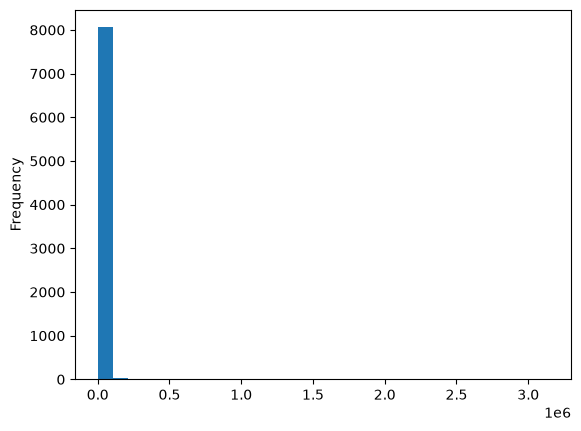

In [18]:
df['poblacion'].plot(kind='hist', bins=30,)

**4.4** Haz lo mismo con otra columna de números.

<Axes: ylabel='Frequency'>

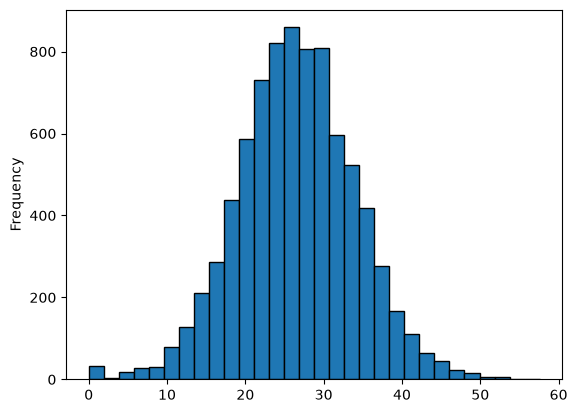

In [19]:
df['abstencion_pct'].plot(kind='hist', bins=30, edgecolor='black')

Lo que he visto y lo que he decidido:

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [20]:
# Mostramos los 5 municipios con mayor población
print(df.nlargest(5, 'poblacion'))

      codigo_municipio  municipio  poblacion    censo  abstencion_pct  \
4357             28079     Madrid    3141991  2363829          26.225   
879               8019  Barcelona    1604555  1136354          32.400   
7222             46250   Valencia     786189   578722          23.457   
6151             41091    Sevilla     693878   541989          28.919   
8112             50297   Zaragoza     664953   498966          27.441   

      votos_blancos_pct  votos_nulos_pct  PP_pct  PSOE_pct  Podemos_pct  \
4357              0.508            0.606  39.956    18.920       21.075   
879               0.755            0.539  15.134    14.010        0.000   
7222              0.574            0.636  35.912    17.336        0.000   
6151              0.856            0.820  33.734    27.813       20.743   
8112              0.759            0.686  33.604    22.702       21.690   

      Ciudadanos_pct  otros_pct  
4357          16.498      2.437  
879           11.279     58.283  
7222    

**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [21]:
# Mostramos los 5 municipios con menor población
print(df.nsmallest(5, 'poblacion'))

      codigo_municipio           municipio  poblacion  censo  abstencion_pct  \
1316              9184   Jaramillo Quemado          5      5            20.0   
6847             45080      Illán de Vacas          6      6             0.0   
6238             42082  Estepa de San Juan          7      8             0.0   
2906             19079         Castilnuevo          8      8             0.0   
4191             26161         Valdemadera          8      8            12.5   

      votos_blancos_pct  votos_nulos_pct   PP_pct  PSOE_pct  Podemos_pct  \
1316                0.0              0.0   50.000     0.000         25.0   
6847                0.0              0.0   66.667    16.667          0.0   
6238               12.5              0.0   50.000     0.000         25.0   
2906                0.0             12.5   87.500     0.000          0.0   
4191                0.0              0.0  100.000     0.000          0.0   

      Ciudadanos_pct  otros_pct  
1316            25.0      0.

comprobamos que no existen valores negativos ni ceros absolutos: las cifras más bajas corresponden a pequeños pueblos con entre 5 y 8 habitantes censados. No se trata de errores informáticos ni valores nulos disfrazados, sino de casos reales de despoblación extrema en el ámbito rural español, por lo que son perfectamente válidos

**5.3** Haz el diagrama de caja de esa columna.

<Axes: >

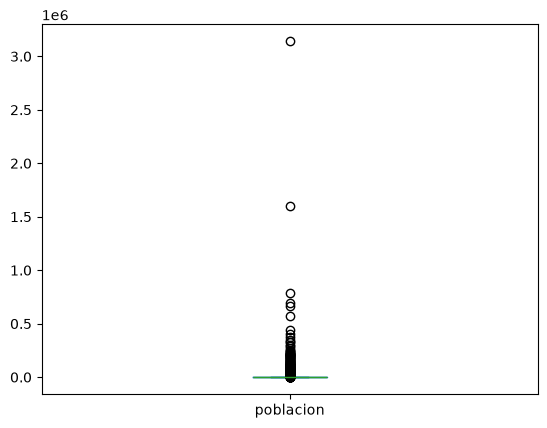

In [22]:
df['poblacion'].plot(kind='box')

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [23]:
# Frecuencia absoluta (número de apariciones) de los municipios
print("Frecuencia Absoluta")
print(df['municipio'].value_counts())

# Frecuencia relativa (en porcentaje)
print("Frecuencia Relativa (%)")
print(df['municipio'].value_counts(normalize=True) * 100)

Frecuencia Absoluta
municipio
Sancti-Spíritus          2
La Zarza                 2
Arroyomolinos            2
Rebollar                 2
Cabanes                  2
                        ..
Biel                     1
Marracos                 1
Villamayor de Gállego    1
Ceuta                    1
Melilla                  1
Name: count, Length: 8102, dtype: int64
Frecuencia Relativa (%)
municipio
Sancti-Spíritus          0.024634
La Zarza                 0.024634
Arroyomolinos            0.024634
Rebollar                 0.024634
Cabanes                  0.024634
                           ...   
Biel                     0.012317
Marracos                 0.012317
Villamayor de Gállego    0.012317
Ceuta                    0.012317
Melilla                  0.012317
Name: proportion, Length: 8102, dtype: float64


**6.2** Dibújalo en barras.

<Axes: xlabel='municipio'>

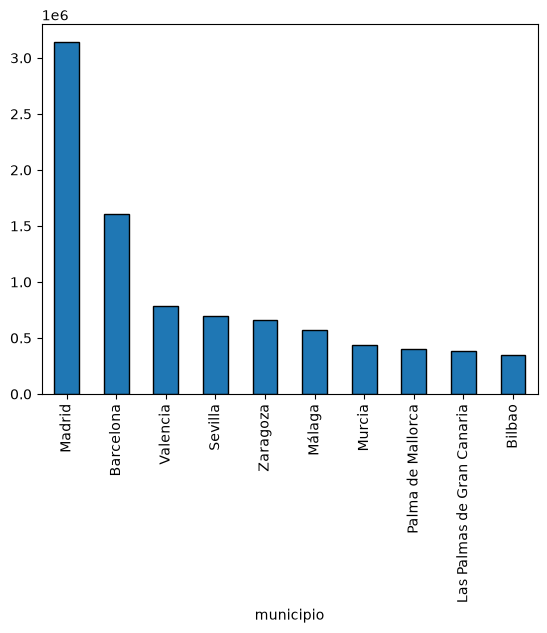

In [24]:
# Gráfico de barras de los 10 municipios con mayor población
df.sort_values(by='poblacion', ascending=False).head(10).set_index('municipio')['poblacion'].plot(kind='bar', edgecolor='black')

Lo que he visto y lo que he decidido:

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [25]:
# Creamos una columna auxiliar para clasificar los municipios por tamaño de población.
df['tipo_municipio'] = pd.cut(
    df['poblacion'], 
    bins=[0, 5000, 50000, df['poblacion'].max()], 
    labels=['Pequeño (<5k)', 'Mediano (5k-50k)', 'Grande (>50k)']
)

# Comparamos la media de los porcentajes de voto (por ejemplo, PP y PSOE) según el tipo de municipio
print(df.groupby('tipo_municipio')[['PP_pct', 'PSOE_pct']].mean())

                     PP_pct   PSOE_pct
tipo_municipio                        
Pequeño (<5k)     41.337542  23.613460
Mediano (5k-50k)  31.172566  23.425088
Grande (>50k)     32.514890  21.991255


**7.2** Haz otra comparación con otra columna de grupos.

In [26]:
# Calculamos la mediana de la abstención para dividir los municipios en dos grupos 
mediana_abstencion = df['abstencion_pct'].median()

# Creamos los dos grupos de manera clásica con filtros
abstencion_baja = df[df['abstencion_pct'] <= mediana_abstencion]
abstencion_alta = df[df['abstencion_pct'] > mediana_abstencion]

# Comparamos la media de votos en blanco y nulos entre los dos tipos de abstención
print("Municipios con Abstención Baja (por debajo de la mediana)")
print(abstencion_baja[['votos_blancos_pct', 'votos_nulos_pct']].mean())

print("Municipios con Abstención Alta (por encima de la mediana)")
print(abstencion_alta[['votos_blancos_pct', 'votos_nulos_pct']].mean())

Municipios con Abstención Baja (por debajo de la mediana)
votos_blancos_pct    0.826229
votos_nulos_pct      1.138692
dtype: float64
Municipios con Abstención Alta (por encima de la mediana)
votos_blancos_pct    0.945337
votos_nulos_pct      1.119004
dtype: float64


**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [27]:
# Comprobamos el número de municipios (filas) en cada grupo de abstención
print("Número de municipios con abstención baja/moderada:", len(abstencion_baja))
print("Número de municipios con abstención alta:", len(abstencion_alta))

Número de municipios con abstención baja/moderada: 4061
Número de municipios con abstención alta: 4058


Lo que he visto y lo que he decidido:

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [28]:
correlacion = df[['poblacion', 'censo']].corr()
print(correlacion)

           poblacion     censo
poblacion   1.000000  0.999112
censo       0.999112  1.000000


**8.2** Haz el gráfico de puntos de esas dos columnas.

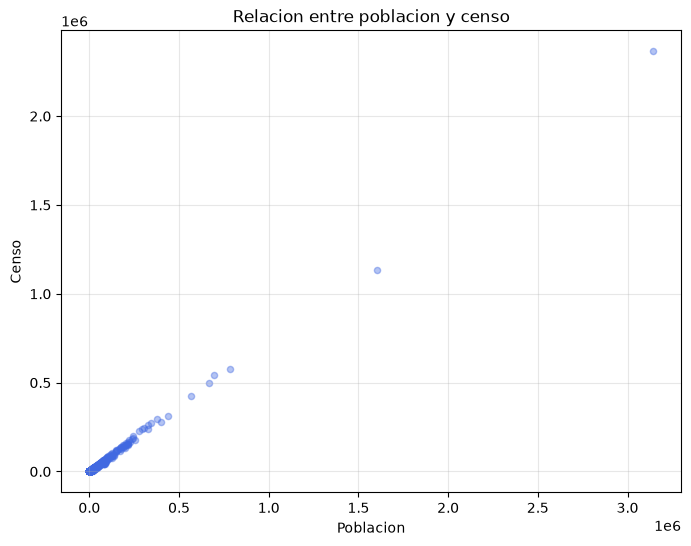

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(df["poblacion"], df["censo"], alpha=0.4, s=20, color="royalblue")
plt.title("Relacion entre poblacion y censo")
plt.xlabel("Poblacion")
plt.ylabel("Censo")
plt.grid(True, alpha=0.3)
plt.show()


La relacion entre la poblacion y el censo es muy fuerte. Los municipios ms grandes suelen tener tambien un censo mayor, lo que confirma una asociacion casi lineal entre ambas variables.

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

1. La poblacion y el censo estan muy correlacionados, lo que indica que los municipios grandes suelen tener mas habitantes censados.
2. La mayoria de municipios tienen poblacion pequeña y una distribucion muy desigual, con varias ciudades muy grandes que elevan la media.
3. No hay huecos ni filas duplicadas, asi que el dataset esta limpio y listo para la app.
4. He dejado solo las columnas mas utiles para la pregunta y he normalizado los nombres para que el analisis sea mas claro.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [30]:
df.to_csv("datos/datos_limpios.csv", index=False)
print("Archivo guardado: datos/datos_limpios.csv")
print(df.head())


Archivo guardado: datos/datos_limpios.csv
   codigo_municipio         municipio  poblacion  censo  abstencion_pct  \
0              1001  Alegría-Dulantzi       2882   1979          32.340   
1              1002           Amurrio      10263   8124          29.567   
2              1003           Aramaio       1518   1190          34.286   
3              1004        Artziniega       1829   1399          27.949   
4              1006           Armiñón        244    175          20.000   

   votos_blancos_pct  votos_nulos_pct  PP_pct  PSOE_pct  Podemos_pct  \
0              0.523            1.568  11.949    15.310       34.802   
1              0.542            1.188   8.668    10.346       33.432   
2              0.256            1.023   1.662     1.535       25.192   
3              0.794            1.290  12.897     7.044       29.365   
4              0.000            0.000  25.714    12.857       34.286   

   Ciudadanos_pct  otros_pct    tipo_municipio  
0           4.630     31.